# Care-Eat 공통 식단 최적화 — 다목적 알고리즘 비교·선정·하이퍼파라미터 조정·검증

**흐름**
1. **1단계 비교** — NSGA-II · NSGA-III · SPEA2 · MOEA/D 를 *같은 연산자·같은 평가 횟수*로 사례 A·B·C 에서 10회씩 실행 → Table 1·2, 최적 알고리즘 자동 선정
2. **2단계 격자 탐색** — 선정된 알고리즘의 하이퍼파라미터 27개 조합 × 사례 A·B × 조정용 시드 3개 → Friedman 평균 순위로 최적 조합 결정 (Table 3)
3. **3단계 검증** — 조정된 설정 vs 기본 설정(+ 현재 앱의 NSGA-II)을 *새 시드 10개*로 A·B·C 에서 비교 → Table 4

**준비**
```
pip install "pymoo>=0.6.2" joblib scipy pandas matplotlib openpyxl python-docx tqdm
```
- 이 노트북과 `moea_core.py` 를 같은 폴더(`backend/scripts/`)에 두고 실행합니다.
- 실행 한 번은 약 2분(평가 22,650회). 전체 약 490회 실행 → **코어 8개 기준 약 2시간**. 중간에 꺼져도 결과 JSON 이 남아 있어 다시 실행하면 이어서 진행합니다.
- 먼저 `QUICK_TEST = True` 로 몇 분 안에 끝까지 돌려 보고, 문제가 없으면 `False` 로 바꿔 본 실험을 돌리세요.

## 0. 설정

In [2]:
import os, sys, json, itertools, time
from pathlib import Path

QUICK_TEST = False          # True: 작은 예산으로 전체 흐름만 확인 · False: 본 실험

HERE = Path.cwd()                                   # backend/scripts
BACKEND = Path(os.environ.get("CAREEAT_BACKEND", HERE.parent)).resolve()
assert (BACKEND / "diet").exists(), f"backend 폴더를 찾지 못했습니다: {BACKEND}"
os.environ["CAREEAT_BACKEND"] = str(BACKEND)
# 병렬 작업자도 같은 경로를 쓰도록 환경변수로 넘김
os.environ["PYTHONPATH"] = os.pathsep.join([str(HERE), str(BACKEND), os.environ.get("PYTHONPATH", "")])
for p in (str(HERE), str(BACKEND)):
    if p not in sys.path: sys.path.insert(0, p)

N_JOBS = max(1, (os.cpu_count() or 2) - 1)          # 동시에 돌릴 실행 수

if QUICK_TEST:
    BUDGET = 600
    SEEDS_COMPARE, SEEDS_TUNE, SEEDS_VALID = [1, 2], [101], [201, 202]
    OUT = HERE / "moea_results_quick"
else:
    BUDGET = 22650                                  # 150 × 151 — 현재 앱(NSGA-II 150개 × 150세대)과 같은 평가 횟수
    SEEDS_COMPARE, SEEDS_TUNE, SEEDS_VALID = list(range(1, 11)), [101, 102, 103], list(range(201, 211))
    OUT = HERE / "moea_results"
OUT.mkdir(exist_ok=True)
ALPHA = 0.05
print("backend:", BACKEND, "| 결과:", OUT, "| 병렬:", N_JOBS, "| 평가 예산:", BUDGET)

backend: C:\dev\survey-app\backend | 결과: c:\dev\survey-app\backend\scripts\moea_results | 병렬: 19 | 평가 예산: 22650


In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import kruskal, mannwhitneyu, friedmanchisquare
from pymoo.indicators.hv import HV
from pymoo.indicators.igd_plus import IGDPlus
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
import pymoo, moea_core as M
from diet.moo_metrics import select_balanced
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda it, **k: it
print("pymoo", pymoo.__version__)

ALGS = ["NSGA2", "NSGA3", "SPEA2", "MOEAD"]
LABEL = {"NSGA2": "NSGA-II", "NSGA3": "NSGA-III", "SPEA2": "SPEA2", "MOEAD": "MOEA/D"}
INSTS = ["A", "B", "C"]
INST_LABEL = {"A": "Instance A (baseline, 3 obj.)", "B": "Instance B (facility plan, 3 obj.)", "C": "Instance C (budget 950 KRW, 4 obj.)"}

# 공통 설정 — S0: 기본(변이 4) · S1: 변이 2 (설정 하나에만 유리한 결론을 피하려고 두 가지로 비교)
DEFAULTS = {
    "NSGA2": dict(pop_size=150, cx=0.9, mut=4),
    "SPEA2": dict(pop_size=150, cx=0.9, mut=4),
    "NSGA3": dict(ref_level=1, cx=0.9, mut=4),
    "MOEAD": dict(ref_level=1, n_neighbors=20, cx=0.9, mut=4),
}
SETTINGS = {"S0": {}, "S1": {"mut": 2}}

# 격자 — 알고리즘마다 3 × 3 × 3 = 27 조합
GRIDS = {
    "NSGA2": dict(pop_size=[100, 150, 200], cx=[0.7, 0.9, 1.0], mut=[1, 2, 4]),
    "SPEA2": dict(pop_size=[100, 150, 200], cx=[0.7, 0.9, 1.0], mut=[1, 2, 4]),
    "NSGA3": dict(ref_level=[0, 1, 2], cx=[0.7, 0.9, 1.0], mut=[1, 2, 4]),
    "MOEAD": dict(ref_level=[0, 1, 2], n_neighbors=[10, 20, 30], mut=[1, 2, 4]),
}

pymoo 0.6.1.6


c:\Users\HyeRi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 공통 함수 — 실행 · 지표 · 통계 · 논문형 표
- **HV** (초부피, 클수록 좋음): 같은 단계·같은 사례에서 모든 실행이 찾은 해 전체의 최솟값·최댓값으로 0–1 정규화, 기준점 1.1 (모든 알고리즘의 해가 기준 상자 안에 들어오므로 진 알고리즘끼리도 비교 가능)
- **IGD+** (작을수록 좋음): 위 합집합 비지배해를 기준 전선으로 사용
- **Spacing** (작을수록 고르게 분포): Schott 간격
- **Selected f1** (작을수록 좋음): 앱이 실제로 고르는 균형 해(`select_balanced`)의 영양 위반 점수

In [4]:
def run_jobs(jobs, desc):
    todo = [j for j in jobs if not M.job_path(j).exists()]
    print(f"{desc}: 전체 {len(jobs)} · 남은 실행 {len(todo)}")
    if todo:
        it = Parallel(n_jobs=N_JOBS, return_as="generator_unordered")(delayed(M.run_one)(j) for j in todo)
        for _ in tqdm(it, total=len(todo), desc=desc): pass
    rows = [json.load(open(M.job_path(j), encoding="utf-8")) for j in jobs]
    df = pd.DataFrame(rows)
    df["F"] = df["F"].apply(np.array)
    return df

def make_job(stage, alg, inst, seed, params, setting, tag=None):
    tag = tag or f"{inst}_{alg}_{setting}_s{seed}"
    return dict(stage=stage, alg=alg, instance=inst, seed=int(seed), params=params, setting=setting,
                tag=tag, budget=BUDGET, out_dir=str(OUT))

_nds = NonDominatedSorting()
def nondom(F):
    F = np.unique(np.asarray(F, float), axis=0)
    return F[_nds.do(F, only_non_dominated_front=True)]

def spacing(F):
    if len(F) < 3: return np.nan
    D = np.abs(F[:, None, :] - F[None, :, :]).sum(-1); np.fill_diagonal(D, np.inf)
    d = D.min(1); return float(np.sqrt(((d - d.mean()) ** 2).sum() / (len(d) - 1)))

def add_metrics(df):
    # 사례별로 모든 실행의 합집합 비지배해를 기준으로 정규화 → HV·IGD+·Spacing·선택해 f1
    df = df.copy()
    for inst, g in df.groupby("instance"):
        allF = np.vstack(g["F"].values)
        ref = nondom(allF)                                   # IGD+ 기준 전선 = 합집합 비지배해
        # 정규화: 이상점 = 전체 최솟값, 최악점 = 모든 실행이 찾은 해 전체의 최댓값
        # (합집합 비지배해의 최댓값을 쓰면 한 알고리즘이 압도할 때 나머지가 기준 상자 밖으로 밀려 HV = 0)
        ideal, nadir = allF.min(0), allF.max(0)
        span = np.where(nadir - ideal > 1e-12, nadir - ideal, 1.0)
        Z = (ref - ideal) / span
        hv = HV(ref_point=np.full(Z.shape[1], 1.1)); igd = IGDPlus(Z)
        for i in g.index:
            F = nondom(df.at[i, "F"]); N = (F - ideal) / span
            df.at[i, "HV"] = float(hv(N)); df.at[i, "IGD+"] = float(igd(N))
            df.at[i, "Spacing"] = spacing(N); df.at[i, "N_ND"] = len(F)
            df.at[i, "Selected f1"] = float(F[select_balanced(F)[0], 0])
    df["Time (s)"] = df["sec"]
    return df

METRICS = {"HV": "max", "IGD+": "min", "Spacing": "min", "Selected f1": "min", "Time (s)": "min"}
ARROW = {"max": "↑", "min": "↓"}

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for r, i in enumerate(o):
        run = max(run, min(1.0, (m - r) * p[i])); adj[i] = run
    return adj

def a12(x, y):
    # Vargha–Delaney A12: x 가 y 보다 클 확률 (0.5 = 차이 없음)
    x, y = np.asarray(x), np.asarray(y)
    return float(((x[:, None] > y[None]).sum() + 0.5 * (x[:, None] == y[None]).sum()) / (len(x) * len(y)))

def fmt_p(p):
    return "< .001" if p < 0.001 else f"{p:.3f}".replace("0.", ".", 1)

In [5]:
# ── 논문형 표: 행 = 지표, 열 = 그룹별 Mean ± SD + 검정 통계량 + p, 최고값 굵게 ──
from IPython.display import display, HTML

class PaperTable:
    def __init__(self, title, header, rows, bold, note, sections=None):
        self.title, self.header, self.rows, self.bold, self.note = title, header, rows, bold, note
        self.sections = sections or {}            # {행 번호: 소제목}
    def html(self):
        th = "".join(f"<th style='padding:4px 10px;border-bottom:1px solid currentColor;text-align:center'>{h}</th>" for h in self.header)
        body = ""
        for r, row in enumerate(self.rows):
            if r in self.sections:
                body += f"<tr><td colspan={len(self.header)} style='padding:6px 10px 2px;font-style:italic;text-align:left'>{self.sections[r]}</td></tr>"
            tds = "".join(f"<td style='padding:3px 10px;text-align:{'left' if c==0 else 'center'}'>{'<b>'+v+'</b>' if (r,c) in self.bold else v}</td>" for c, v in enumerate(row))
            body += f"<tr>{tds}</tr>"
        return (f"<div style='font-family:Times New Roman,serif;max-width:1000px'><p><b>{self.title}</b></p>"
                f"<table style='border-collapse:collapse;border-top:1.5px solid currentColor;border-bottom:1.5px solid currentColor'>"
                f"<thead><tr>{th}</tr></thead><tbody>{body}</tbody></table>"
                f"<p style='font-size:90%'><i>Note.</i> {self.note}</p></div>")
    def show(self): display(HTML(self.html()))
    def frame(self):
        return pd.DataFrame(self.rows, columns=self.header)

def metric_table(df, group_col, groups, glabel, title, note_extra="", by_instance=True, metrics=None):
    # 그룹(알고리즘 또는 설정) 간 Kruskal–Wallis(3개 이상) / Mann–Whitney U(2개)
    metrics = metrics or ["HV", "IGD+", "Spacing", "Selected f1", "Time (s)"]
    k = len(groups); test = "H" if k > 2 else "U"
    header = ["Metric"] + [f"{glabel[g]}<br>Mean ± SD" for g in groups] + [test, "p-value"]
    rows, bold, sections = [], set(), {}
    for inst in (INSTS if by_instance else [None]):
        d = df if inst is None else df[df.instance == inst]
        if not len(d): continue
        if inst is not None: sections[len(rows)] = INST_LABEL[inst]
        for m in metrics:
            vals = [d[d[group_col] == g][m].dropna().values for g in groups]
            means = [v.mean() if len(v) else np.nan for v in vals]
            dec = 1 if m == "Time (s)" else 4
            cells = [f"{v.mean():.{dec}f} ± {v.std(ddof=1) if len(v)>1 else 0:.{dec}f}" if len(v) else "–" for v in vals]
            try:
                stat, p = (kruskal(*vals) if k > 2 else mannwhitneyu(vals[0], vals[1], alternative="two-sided"))
                st, ps = f"{stat:.2f}", fmt_p(p)
            except ValueError:
                st, ps = "–", "–"
            r = len(rows)
            best = int(np.nanargmax(means) if METRICS[m] == "max" else np.nanargmin(means))
            bold.add((r, best + 1))
            rows.append([f"{m} {ARROW[METRICS[m]]}"] + cells + [st, ps])
    test_name = "Kruskal–Wallis H test" if k > 2 else "two-sided Mann–Whitney U test"
    n = int(df.groupby([group_col] + (["instance"] if by_instance else [])).size().min())
    note = (f"Values are mean ± standard deviation over {n} independent runs per cell. Bold indicates the best mean value per metric "
            f"(↑ higher is better, ↓ lower is better). Objectives were normalised to [0, 1] by the minimum and maximum values of all "
            f"solutions obtained by all runs for the same instance; HV used the reference point (1.1, …, 1.1), and IGD+ used the "
            f"non-dominated set of the union of all runs as the reference front. "
            f"{test} and p-values are from the {test_name}. {note_extra}")
    return PaperTable(title, header, rows, bold, note, sections)

def pairwise_table(df, groups, glabel, title, metrics=("HV", "IGD+")):
    header = ["Instance", "Comparison", "Metric", "U", "p (Holm)", "A12", "Better"]
    rows, bold = [], set()
    for inst in INSTS:
        d = df[df.instance == inst]
        if not len(d): continue
        for m in metrics:
            res = []
            for a, b in itertools.combinations(groups, 2):
                x, y = d[d.alg == a][m].values, d[d.alg == b][m].values
                U, p = mannwhitneyu(x, y, alternative="two-sided")
                A = a12(x, y) if METRICS[m] == "max" else a12(-x, -y)   # A12 > 0.5 이면 a 가 우수
                res.append([a, b, U, p, A])
            ph = holm([r[3] for r in res])
            for (a, b, U, p, A), q in zip(res, ph):
                better = (glabel[a] if A > 0.5 else glabel[b]) if q < ALPHA else "n.s."
                r = len(rows)
                if q < ALPHA: bold.add((r, 6))
                rows.append([inst, f"{glabel[a]} vs {glabel[b]}", f"{m} {ARROW[METRICS[m]]}", f"{U:.1f}", fmt_p(q), f"{A:.2f}", better])
    note = ("Two-sided Mann–Whitney U tests with Holm correction within each instance and metric (6 comparisons). "
            "A12 is the Vargha–Delaney effect size for the first algorithm being better (0.5 = no difference; ≥ 0.71 large). "
            f"'n.s.' = not significant at α = {ALPHA}.")
    return PaperTable(title, header, rows, bold, note)

def save_tables(tables, stem):
    # 표 → Word(논문 3선 표) + Excel
    from docx import Document
    from docx.shared import Pt
    from docx.oxml import parse_xml
    from docx.oxml.ns import nsdecls
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    from docx.enum.section import WD_ORIENT
    doc = Document()
    sec = doc.sections[0]; sec.orientation = WD_ORIENT.LANDSCAPE
    sec.page_width, sec.page_height = sec.page_height, sec.page_width
    st = doc.styles["Normal"]; st.font.name = "Times New Roman"; st.font.size = Pt(10)
    def border(cell, **sides):
        tcPr = cell._tc.get_or_add_tcPr()
        xml = "".join(f'<w:{s} w:val="single" w:sz="{v}" w:space="0" w:color="000000"/>' for s, v in sides.items())
        tcPr.append(parse_xml(f'<w:tcBorders {nsdecls("w")}>{xml}</w:tcBorders>'))
    with pd.ExcelWriter(OUT / f"{stem}.xlsx") as xw:
        for i, t in enumerate(tables):
            p = doc.add_paragraph(); r = p.add_run(t.title.split(".")[0] + ". "); r.bold = True
            p.add_run(".".join(t.title.split(".")[1:]).strip()).italic = True
            hdr = [h.replace("<br>", "\n") for h in t.header]
            nrow = 1 + len(t.rows) + len(t.sections)
            tb = doc.add_table(rows=nrow, cols=len(hdr))
            for c, h in enumerate(hdr):
                cell = tb.cell(0, c); cell.text = h; cell.paragraphs[0].runs[0].bold = False
                border(cell, top=12, bottom=6)
            ri = 1
            for r, row in enumerate(t.rows):
                if r in t.sections:
                    m = tb.cell(ri, 0).merge(tb.cell(ri, len(hdr) - 1)); m.text = t.sections[r]
                    m.paragraphs[0].runs[0].italic = True; ri += 1
                for c, v in enumerate(row):
                    cell = tb.cell(ri, c); cell.text = v
                    run = cell.paragraphs[0].runs[0]; run.bold = (r, c) in t.bold
                    if c: cell.paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER
                ri += 1
            for c in range(len(hdr)):
                border(tb.cell(nrow - 1, c), bottom=12)
            for row in tb.rows:
                for cell in row.cells:
                    for par in cell.paragraphs:
                        for run in par.runs: run.font.size = Pt(9)
            n = doc.add_paragraph(); n.add_run("Note. ").italic = True; n.add_run(t.note).font.size = Pt(9)
            doc.add_paragraph()
            df_ = t.frame(); df_.columns = hdr
            df_.to_excel(xw, sheet_name=f"Table{i+1}"[:31], index=False)
    doc.save(OUT / f"{stem}.docx")
    print("저장:", OUT / f"{stem}.docx", "·", OUT / f"{stem}.xlsx")

## 2. 1단계 — 네 알고리즘을 같은 설정에서 비교
- 같은 표집(정수 무작위) · 같은 교차(균등 교차, 확률 0.9) · 같은 변이(무작위 재설정, 염색체당 평균 4개 / S1 은 2개) · 같은 평가 횟수
- NSGA-III · MOEA/D 는 기준 방향 수(3목적 153개, 4목적 165개)가 집단 크기를 정합니다 — NSGA-II·SPEA2 의 150개와 비슷하게 맞췄습니다.
- 목적함수 크기가 서로 달라 모든 알고리즘에 같은 고정 척도(무작위 해 2,000개의 1–99 백분위)를 적용합니다 (pymoo MOEA/D 는 스스로 정규화하지 않기 때문).

In [6]:
jobs1 = [make_job("stage1", a, i, s, {**DEFAULTS[a], **SETTINGS[st]}, st)
         for st in SETTINGS for i in INSTS for a in ALGS for s in SEEDS_COMPARE]
t0 = time.time()
R1 = run_jobs(jobs1, "1단계 비교")
R1 = pd.concat([add_metrics(R1[R1.setting == st]) for st in SETTINGS])   # 설정별로 따로 정규화
print(f"{(time.time()-t0)/60:.1f}분")
R1.groupby(["setting", "instance", "alg"])[["HV", "IGD+", "Spacing", "Selected f1", "Time (s)"]].mean().round(4)

1단계 비교: 전체 240 · 남은 실행 240


1단계 비교: 100%|██████████| 240/240 [54:55<00:00, 13.73s/it]  
C:\Users\HyeRi\AppData\Local\Temp\ipykernel_28800\3251902923.py:41: Pandas4Warning: Setting a value on a DataFrame via .at with a key that does not exist in the index is deprecated and will raise a KeyError in a future version. Use .loc instead.
  df.at[i, "HV"] = float(hv(N)); df.at[i, "IGD+"] = float(igd(N))
C:\Users\HyeRi\AppData\Local\Temp\ipykernel_28800\3251902923.py:41: Pandas4Warning: Setting a value on a DataFrame via .at with a key that does not exist in the index is deprecated and will raise a KeyError in a future version. Use .loc instead.
  df.at[i, "HV"] = float(hv(N)); df.at[i, "IGD+"] = float(igd(N))
C:\Users\HyeRi\AppData\Local\Temp\ipykernel_28800\3251902923.py:42: Pandas4Warning: Setting a value on a DataFrame via .at with a key that does not exist in the index is deprecated and will raise a KeyError in a future version. Use .loc instead.
  df.at[i, "Spacing"] = spacing(N); df.at[i, "N_ND"] = len(F)
C:\Users

55.0분


HV    IGD+  Spacing  Selected f1  Time (s)
setting instance alg                                                  
S0      A        MOEAD  1.1829  0.0395   0.0203       0.2115   199.665
                 NSGA2  0.6012  0.4764   0.0278       0.2530   188.690
                 NSGA3  0.7872  0.2496   0.0361       0.2357   190.137
                 SPEA2  0.8797  0.2376   0.0197       0.2273   185.850
        B        MOEAD  1.1916  0.0550   0.0206       0.3089   204.099
                 NSGA2  0.6187  0.4935   0.0281       0.4726   190.074
                 NSGA3  0.7186  0.3123   0.0347       0.4131   193.729
                 SPEA2  0.8971  0.2532   0.0177       0.3788   191.485
        C        MOEAD  1.2746  0.0293   0.0265       0.2318   348.745
                 NSGA2  0.6895  0.4622   0.0574       0.2705   289.110
                 NSGA3  0.9617  0.1687   0.0450       0.2384   424.232
                 SPEA2  0.9477  0.2211   0.0239       0.2478   467.831
S1      A        MOEAD  1.1706  0.0510   0.0173       0.2180   203.637
                 NSGA2  0.6089  0.4949   0.0291       0.2451   214.327
                 NSGA3  0.8539  0.2280   0.0300       0.2194   198.002
                 SPEA2  0.9002  0.2444   0.0178       0.2229   191.582
        B        MOEAD  1.2143  0.0273   0.0167       0.3156   202.394
                 NSGA2  0.6179  0.4809   0.0274       0.4475   193.754
                 NSGA3  0.8695  0.2088   0.0256       0.3351   193.249
                 SPEA2  0.9752  0.1813   0.0131       0.3477   193.552
        C        MOEAD  1.2769  0.0348   0.0245       0.2424   372.159
                 NSGA2  0.6577  0.4763   0.0598       0.2659   253.913
                 NSGA3  0.9616  0.1657   0.0399       0.2246   263.446
                 SPEA2  0.9943  0.1897   0.0309       0.2291   290.071

In [7]:
T1 = metric_table(R1[R1.setting == "S0"], "alg", ALGS, LABEL,
                  "Table 1. Comparative Performance of Multi-Objective Optimization Algorithms",
                  note_extra=f"All algorithms used the same integer sampling, uniform crossover (p = 0.9), random-reset mutation "
                             f"(4 genes per chromosome on average) and the same budget of {BUDGET:,} function evaluations.")
T1.show()
T2 = pairwise_table(R1[R1.setting == "S0"], ALGS, LABEL, "Table 2. Pairwise Comparisons of Algorithms (Holm-adjusted)")
T2.show()
T1b = metric_table(R1[R1.setting == "S1"], "alg", ALGS, LABEL,
                   "Table S1. Comparative Performance under an Alternative Common Setting (2 mutated genes)",
                   note_extra="Identical to Table 1 except for the mutation strength.")
T1b.show()

Instance,Comparison,Metric,U,p (Holm),A12,Better
A,NSGA-II vs NSGA-III,HV ↑,0.0,.001,0.00,NSGA-III
A,NSGA-II vs SPEA2,HV ↑,0.0,.001,0.00,SPEA2
A,NSGA-II vs MOEA/D,HV ↑,0.0,.001,0.00,MOEA/D
A,NSGA-III vs SPEA2,HV ↑,11.0,.004,0.11,SPEA2
A,NSGA-III vs MOEA/D,HV ↑,0.0,.001,0.00,MOEA/D
A,SPEA2 vs MOEA/D,HV ↑,0.0,.001,0.00,MOEA/D
A,NSGA-II vs NSGA-III,IGD+ ↓,100.0,.001,0.00,NSGA-III
A,NSGA-II vs SPEA2,IGD+ ↓,100.0,.001,0.00,SPEA2
A,NSGA-II vs MOEA/D,IGD+ ↓,100.0,.001,0.00,MOEA/D
A,NSGA-III vs SPEA2,IGD+ ↓,68.0,.186,0.32,n.s.


In [8]:
# 최적 알고리즘 선정 — 사례·설정·시드마다 HV·IGD+ 순위를 매겨 평균 (낮을수록 좋음)
rk = []
for (st, inst, seed), g in R1.groupby(["setting", "instance", "seed"]):
    g = g.set_index("alg")
    rk.append(pd.DataFrame({"HV": g["HV"].rank(ascending=False), "IGD+": g["IGD+"].rank(ascending=True)}).assign(setting=st, instance=inst))
rk = pd.concat(rk).reset_index()
rank_tab = rk.groupby("alg")[["HV", "IGD+"]].mean()
rank_tab["Mean rank"] = rank_tab.mean(1)
rank_tab = rank_tab.sort_values("Mean rank")
by_case = rk.assign(r=(rk["HV"] + rk["IGD+"]) / 2).pivot_table(index="alg", columns=["setting", "instance"], values="r")
display(rank_tab.rename(index=LABEL).round(2)); display(by_case.rename(index=LABEL).round(2))
BEST_ALG = rank_tab.index[0]
print(f"▶ 선정된 알고리즘: {LABEL[BEST_ALG]}  (HV·IGD+ 평균 순위 {rank_tab.iloc[0]['Mean rank']:.2f})")

C:\Users\HyeRi\AppData\Local\Temp\ipykernel_28800\1157079581.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  rank_tab["Mean rank"] = rank_tab.mean(1)


,HV,IGD+,Mean rank
alg,,,
MOEA/D,1.02,1.00,1.01
SPEA2,2.20,2.45,2.33
NSGA-III,2.78,2.55,2.67
NSGA-II,4.00,4.00,4.00


setting     S0               S1          
instance     A    B     C     A    B    C
alg                                      
MOEA/D    1.00  1.0  1.00  1.05  1.0  1.0
NSGA-II   4.00  4.0  4.00  4.00  4.0  4.0
NSGA-III  2.85  2.9  2.35  2.60  2.8  2.5
SPEA2     2.15  2.1  2.65  2.35  2.2  2.5

▶ 선정된 알고리즘: MOEA/D  (HV·IGD+ 평균 순위 1.01)


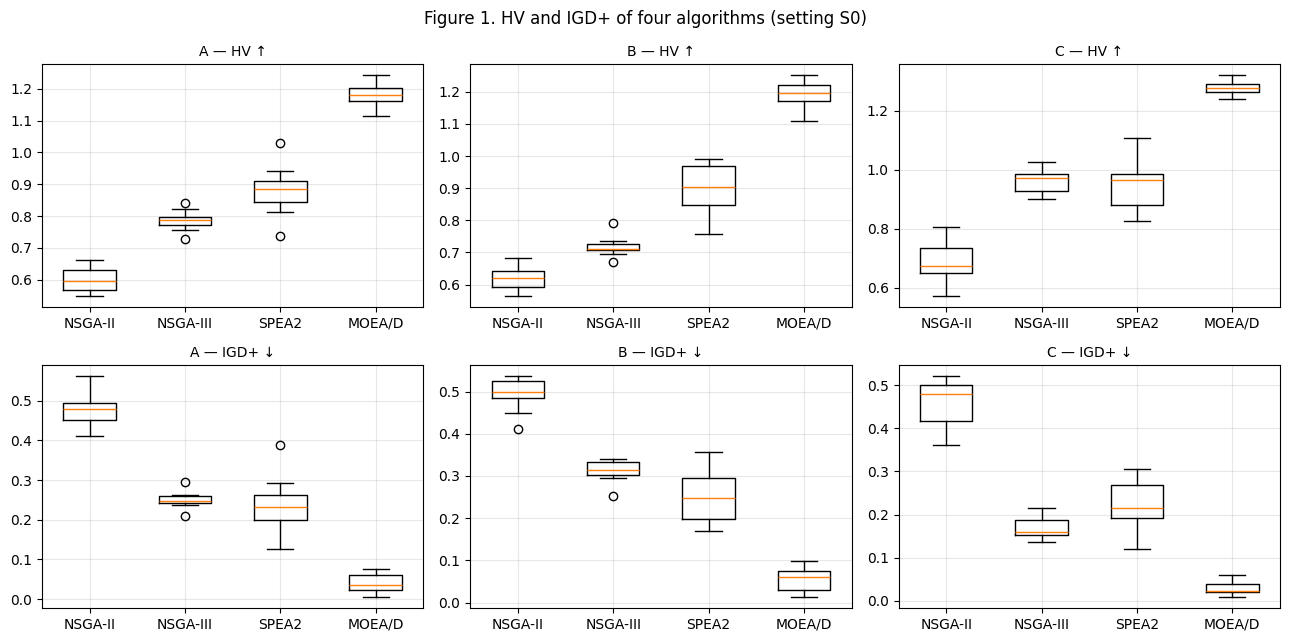

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for c, inst in enumerate(INSTS):
    d = R1[(R1.setting == "S0") & (R1.instance == inst)]
    for r, m in enumerate(["HV", "IGD+"]):
        ax = axes[r, c]
        ax.boxplot([d[d.alg == a][m] for a in ALGS], tick_labels=[LABEL[a] for a in ALGS], widths=0.55)
        ax.set_title(f"{inst} — {m} {ARROW[METRICS[m]]}", fontsize=10); ax.grid(alpha=.3)
fig.suptitle("Figure 1. HV and IGD+ of four algorithms (setting S0)"); fig.tight_layout()
fig.savefig(OUT / "fig1_stage1_box.png", dpi=200); plt.show()

## 3. 2단계 — 선정된 알고리즘의 격자 탐색
- 27개 조합 × 사례 A·B × **조정용 시드**(101–103) — 검증용 시드와 겹치지 않게 분리
- 사례·시드마다 27개 조합의 HV 순위를 매겨 평균(Friedman 평균 순위)이 가장 낮은 조합을 고릅니다. IGD+ 순위는 동점 처리용으로 씁니다.
- 사례 C(4목적)는 검증에서 *일반화* 확인용으로 남겨 둡니다.

In [10]:
grid = GRIDS[BEST_ALG]; keys = list(grid)
combos = [dict(zip(keys, v)) for v in itertools.product(*grid.values())]
base = {k: v for k, v in DEFAULTS[BEST_ALG].items() if k not in keys}           # 격자에 없는 값은 기본값 유지
def ctag(c): return "_".join(f"{k}{c[k]}" for k in keys)
jobs2 = [make_job("stage2", BEST_ALG, i, s, {**base, **c}, ctag(c), tag=f"{i}_{BEST_ALG}_{ctag(c)}_s{s}")
         for i in ["A", "B"] for c in combos for s in SEEDS_TUNE]
t0 = time.time()
R2 = add_metrics(run_jobs(jobs2, f"2단계 격자 탐색 ({LABEL[BEST_ALG]})"))
for k in keys: R2[k] = R2["params"].apply(lambda p: p[k])
print(f"{(time.time()-t0)/60:.1f}분")

R2["rHV"] = R2.groupby(["instance", "seed"])["HV"].rank(ascending=False)
R2["rIGD"] = R2.groupby(["instance", "seed"])["IGD+"].rank(ascending=True)
G = R2.groupby("setting").agg(**{k: (k, "first") for k in keys}, HV=("HV", "mean"), IGD=("IGD+", "mean"),
                              rank_HV=("rHV", "mean"), rank_IGD=("rIGD", "mean"), sec=("sec", "mean"))
G = G.sort_values(["rank_HV", "rank_IGD"])
blocks = R2.pivot_table(index=["instance", "seed"], columns="setting", values="HV")
fr = friedmanchisquare(*[blocks[c].values for c in blocks.columns]) if blocks.shape[0] > 1 else None
BEST_PARAMS = {**base, **{k: G.iloc[0][k] for k in keys}}
BEST_PARAMS = {k: (int(v) if float(v).is_integer() and k != "cx" else float(v)) for k, v in BEST_PARAMS.items()}
print("Friedman χ² =", f"{fr.statistic:.2f}, p = {fmt_p(fr.pvalue)}" if fr else "(블록이 1개라 생략)")
print("▶ 최적 조합:", BEST_PARAMS, "| 기본값:", DEFAULTS[BEST_ALG])
G.head(10).round(4)

2단계 격자 탐색 (MOEA/D): 전체 162 · 남은 실행 162


2단계 격자 탐색 (MOEA/D):   0%|          | 0/162 [00:03<?, ?it/s]


UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc0 in position 0: invalid start byte

In [ ]:
# Table 3 — 상위 10개 조합 + 기본 조합
PNAME = {"pop_size": "Population", "cx": "Crossover p", "mut": "Mutated genes", "ref_level": "Ref. level", "n_neighbors": "Neighbours T"}
dtag = ctag({k: DEFAULTS[BEST_ALG][k] for k in keys})
show = list(G.index[:10]) + ([dtag] if dtag not in G.index[:10] else [])
header = ["Rank"] + [PNAME[k] for k in keys] + ["HV ↑", "IGD+ ↓", "Mean rank (HV)", "Mean rank (IGD+)", "Time (s)"]
rows, bold = [], set()
for t in show:
    g = G.loc[t]; pos = list(G.index).index(t) + 1
    rows.append([f"{pos}{' (default)' if t == dtag else ''}"] + [f"{g[k]:g}" for k in keys] +
                [f"{g.HV:.4f}", f"{g.IGD:.4f}", f"{g.rank_HV:.2f}", f"{g.rank_IGD:.2f}", f"{g.sec:.1f}"])
for c, col, how in [(len(keys)+1, "HV", "max"), (len(keys)+2, "IGD", "min"), (len(keys)+3, "rank_HV", "min"), (len(keys)+4, "rank_IGD", "min")]:
    vals = G.loc[show, col].values; bold.add((int(np.argmax(vals) if how == "max" else np.argmin(vals)), c))
fr_txt = f"Friedman test across all {len(G)} configurations: χ² = {fr.statistic:.2f}, p {('= ' + fmt_p(fr.pvalue)) if fr.pvalue >= .001 else '< .001'}." if fr else ""
T3 = PaperTable(f"Table 3. Grid Search of {LABEL[BEST_ALG]} Hyperparameters (top 10 of {len(G)} configurations)", header, rows, bold,
                f"Each configuration was run on instances A and B with {len(SEEDS_TUNE)} tuning seeds (seeds disjoint from validation). "
                f"Configurations were ranked within each instance–seed block by HV (IGD+ as tie-breaker); mean ranks are averaged over "
                f"{blocks.shape[0]} blocks (lower is better). {fr_txt} Bold indicates the best value among the listed configurations.")
T3.show()

In [ ]:
# 주효과 · 상호작용
fig, axes = plt.subplots(1, len(keys), figsize=(4 * len(keys), 3.3), sharey=True)
for ax, k in zip(axes, keys):
    me = R2.groupby([k, "instance"])["rHV"].mean().unstack()
    for inst in me.columns: ax.plot(me.index.astype(str), me[inst], "o-", label=f"Instance {inst}")
    ax.plot(me.index.astype(str), me.mean(1), "k--", lw=2, label="Mean")
    ax.set_xlabel(PNAME[k]); ax.grid(alpha=.3)
axes[0].set_ylabel("Mean HV rank (lower = better)"); axes[0].legend(fontsize=8)
fig.suptitle(f"Figure 2. Main effects of {LABEL[BEST_ALG]} hyperparameters"); fig.tight_layout()
fig.savefig(OUT / "fig2_main_effects.png", dpi=200); plt.show()

pairs = list(itertools.combinations(keys, 2))
fig, axes = plt.subplots(1, len(pairs), figsize=(4.6 * len(pairs), 3.6))
Hs = [R2.pivot_table(index=a, columns=b, values="rHV", aggfunc="mean") for a, b in pairs]
vmin, vmax = min(h.values.min() for h in Hs), max(h.values.max() for h in Hs)   # 세 그림 같은 색 척도
for ax, (a, b), H in zip(axes, pairs, Hs):
    im = ax.imshow(H.values, cmap="viridis_r", vmin=vmin, vmax=vmax); ax.set_xticks(range(H.shape[1]), H.columns); ax.set_yticks(range(H.shape[0]), H.index)
    ax.set_xlabel(PNAME[b]); ax.set_ylabel(PNAME[a])
    for (y, x), v in np.ndenumerate(H.values): ax.text(x, y, f"{v:.1f}", ha="center", va="center", fontsize=8,
                                                       color="k" if v < (vmin + vmax) / 2 else "w")
fig.colorbar(im, ax=axes, shrink=.8, label="Mean HV rank")
fig.suptitle("Figure 3. Two-way interactions (mean HV rank)")
fig.savefig(OUT / "fig3_interactions.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. 3단계 — 검증 (새 시드 10개, 사례 A·B·C)
- **Tuned**: 2단계 최적 조합 · **Default**: 같은 알고리즘의 기본 설정 · **Current app**: 지금 앱의 NSGA-II(150개, 교차 0.9, 변이 4)
- 사례 C는 격자 탐색에 쓰지 않았으므로 *다른 문제로의 일반화*를 확인합니다.

In [ ]:
CANDS = {"Tuned": (BEST_ALG, BEST_PARAMS), "Default": (BEST_ALG, DEFAULTS[BEST_ALG])}
if BEST_ALG != "NSGA2": CANDS["Current app"] = ("NSGA2", DEFAULTS["NSGA2"])
if BEST_PARAMS == DEFAULTS[BEST_ALG]:
    print("※ 최적 조합이 기본값과 같습니다 — Tuned 와 Default 는 같은 설정입니다.")
jobs3 = [make_job("stage3", a, i, s, p, name, tag=f"{i}_{name.replace(' ', '')}_s{s}")
         for name, (a, p) in CANDS.items() for i in INSTS for s in SEEDS_VALID]
R3 = add_metrics(run_jobs(jobs3, "3단계 검증"))
VL = {k: k for k in CANDS}
T4 = metric_table(R3, "setting", list(CANDS), VL,
                  f"Table 4. Validation of the Tuned {LABEL[BEST_ALG]} on Unseen Seeds",
                  note_extra=f"Tuned = {BEST_PARAMS}; Default = {DEFAULTS[BEST_ALG]}"
                             + ("; Current app = NSGA-II with population 150, crossover 0.9, 4 mutated genes" if "Current app" in CANDS else "")
                             + f". Validation seeds ({SEEDS_VALID[0]}–{SEEDS_VALID[-1]}) were not used for tuning; instance C was not used for tuning.")
T4.show()

# Tuned vs Default 효과 크기
eff = []
for inst in INSTS:
    d = R3[R3.instance == inst]
    for m in ["HV", "IGD+", "Selected f1"]:
        x, y = d[d.setting == "Tuned"][m].values, d[d.setting == "Default"][m].values
        if np.allclose(x, y): eff.append([inst, m, np.nan, 1.0, 0.5]); continue
        U, p = mannwhitneyu(x, y, alternative="two-sided")
        A = a12(x, y) if METRICS[m] == "max" else a12(-x, -y)
        eff.append([inst, m, U, p, A])
eff = pd.DataFrame(eff, columns=["instance", "metric", "U", "p", "A12 (Tuned better)"])
eff["p (Holm)"] = holm(eff["p"].values); display(eff.round(4))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, inst in zip(axes, INSTS):
    d = R3[R3.instance == inst]
    ax.boxplot([d[d.setting == k]["HV"] for k in CANDS], tick_labels=list(CANDS), widths=.55)
    ax.set_title(f"Instance {inst} — HV ↑", fontsize=10); ax.grid(alpha=.3)
fig.suptitle(f"Figure 4. Validation on unseen seeds ({LABEL[BEST_ALG]})"); fig.tight_layout()
fig.savefig(OUT / "fig4_validation.png", dpi=200); plt.show()

## 5. 저장

In [ ]:
save_tables([T1, T2, T1b, T3, T4], "MOEA_tables")
cols = ["stage", "alg", "instance", "seed", "setting", "params", "HV", "IGD+", "Spacing", "N_ND", "Selected f1", "Time (s)", "n_eval"]
with pd.ExcelWriter(OUT / "MOEA_raw_runs.xlsx") as xw:
    for name, R in [("stage1_compare", R1), ("stage2_grid", R2), ("stage3_validation", R3)]:
        R.assign(params=R["params"].astype(str))[cols].to_excel(xw, sheet_name=name, index=False)
    G.reset_index().to_excel(xw, sheet_name="grid_ranking", index=False)
    rank_tab.rename(index=LABEL).to_excel(xw, sheet_name="alg_mean_rank")
json.dump({"selected_algorithm": BEST_ALG, "best_params": BEST_PARAMS, "default_params": DEFAULTS[BEST_ALG],
           "budget": BUDGET, "quick_test": QUICK_TEST}, open(OUT / "selected_config.json", "w"), ensure_ascii=False, indent=2)
print("완료 —", OUT)